<a href="https://colab.research.google.com/github/Aswathivalsan/Data_Analytics-Projects/blob/DataVisualization/Assignment_11_Data_Visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install matplotlib

In [ ]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns

# **Load The Taxis Dataset**

In [ ]:
df = sns.load_dataset('taxis')
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [ ]:
df.shape

(6433, 14)

In [ ]:
df.columns

Index(['pickup', 'dropoff', 'passengers', 'distance', 'fare', 'tip', 'tolls',
       'total', 'color', 'payment', 'pickup_zone', 'dropoff_zone',
       'pickup_borough', 'dropoff_borough'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[ns]
 1   dropoff          6433 non-null   datetime64[ns]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   object        
 9   payment          6389 non-null   object        
 10  pickup_zone      6407 non-null   object        
 11  dropoff_zone     6388 non-null   object        
 12  pickup_borough   6407 non-null   object        
 13  dropoff_borough  6388 non-null   object        
dtypes: datetime64[ns](2), float64(5), int64(

In [ ]:
df.describe()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total
count,6433,6433,6433.000000,6433.000000,6433.000000,6433.00000,6433.000000,6433.000000
mean,2019-03-16 08:31:28.514223616,2019-03-16 08:45:49.491217408,1.539251,3.024617,13.091073,1.97922,0.325273,18.517794
min,2019-02-28 23:29:03,2019-02-28 23:32:35,0.000000,0.000000,1.000000,0.00000,0.000000,1.300000
25%,2019-03-08 15:50:34,2019-03-08 16:12:51,1.000000,0.980000,6.500000,0.00000,0.000000,10.800000
50%,2019-03-15 21:46:58,2019-03-15 22:06:44,1.000000,1.640000,9.500000,1.70000,0.000000,14.160000
75%,2019-03-23 17:41:38,2019-03-23 17:51:56,2.000000,3.210000,15.000000,2.80000,0.000000,20.300000
max,2019-03-31 23:43:45,2019-04-01 00:13:58,6.000000,36.700000,150.000000,33.20000,24.020000,174.820000
std,NaN,NaN,1.203768,3.827867,11.551804,2.44856,1.415267,13.815570


# **Handling missing values**

In [ ]:
df.isnull().sum()

,0
pickup,0
dropoff,0
passengers,0
distance,0
fare,0
tip,0
tolls,0
total,0
color,0
payment,44


# **Find the Total number of missing values**

In [ ]:
df.isnull().sum().sum()

np.int64(186)

In [ ]:
num_cols = df.select_dtypes(include=np.number).columns
print(num_cols)

Index(['passengers', 'distance', 'fare', 'tip', 'tolls', 'total'], dtype='object')


# **Fill missing numerical values using median**

In [ ]:
for col in num_cols:
  df[col] = df[col].fillna(df[col].mean())

# **Handle missing categorical values**

In [ ]:
cat_cols = df.select_dtypes(include='object').columns
print(cat_cols)

Index(['color', 'payment', 'pickup_zone', 'dropoff_zone', 'pickup_borough',
       'dropoff_borough'],
      dtype='object')


In [ ]:
# Fill missing categorical values using mode

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

**Handle missing pickup timestamps**

In [ ]:
# Convert pickup column into datetime format

df['pickup'] = pd.to_datetime(df['pickup'], errors='coerce')

# Remove rows with missing pickup timestamps

df = df.dropna(subset=['pickup'])

In [ ]:
df.isnull().sum()

,0
pickup,0
dropoff,0
passengers,0
distance,0
fare,0
tip,0
tolls,0
total,0
color,0
payment,0


In [ ]:
for col in df.select_dtypes(include='category').columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

LINE CHART - Fare over Time

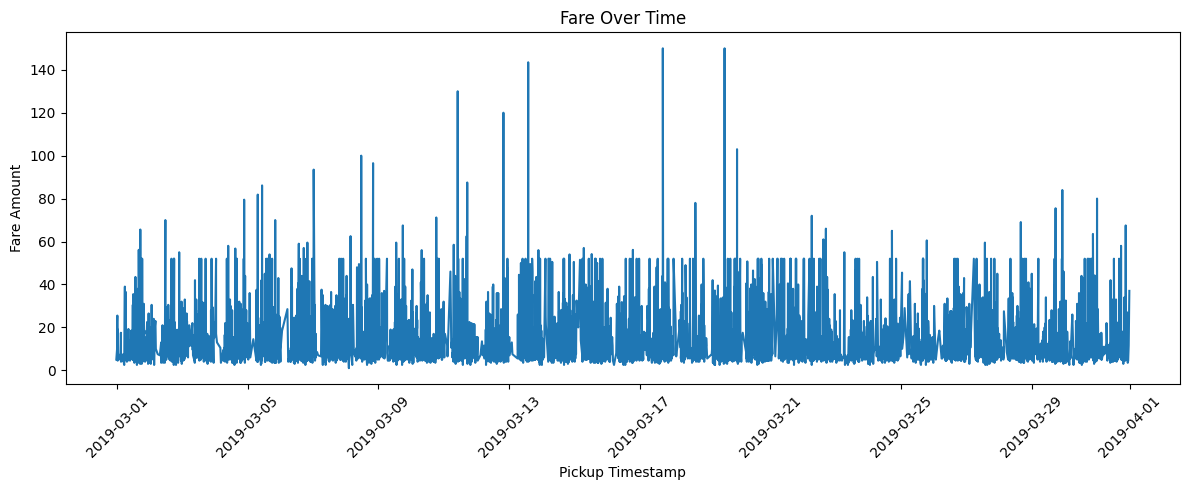

In [ ]:

df = df.sort_values('pickup')
plt.figure(figsize=(12, 5))
plt.plot(df['pickup'], df['fare'])
plt.title('Fare Over Time')
plt.xlabel('Pickup Timestamp')
plt.ylabel('Fare Amount')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

**Bar Chart – Total Fare by Pickup Borough**



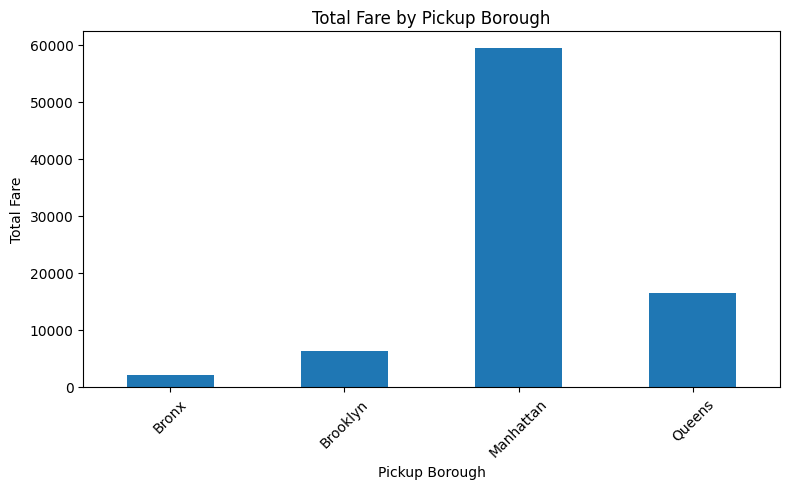

In [ ]:
# Group data by pickup borough and calculate total fare

borough_fare = df.groupby('pickup_borough')['fare'].sum()

# Create bar chart

plt.figure(figsize=(8, 5))

borough_fare.plot(kind='bar')

plt.title('Total Fare by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

pie chart

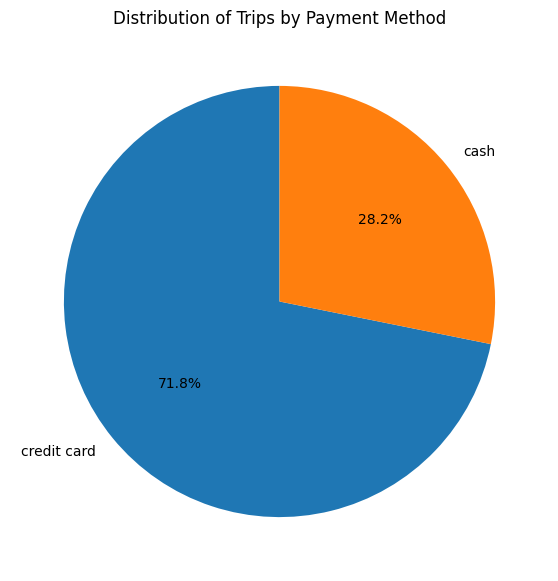

In [ ]:
# Count trips by payment method

payment_counts = df['payment'].value_counts()

# Create pie chart

plt.figure(figsize=(7, 7))

plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Distribution of Trips by Payment Method')

plt.show()

Histogram

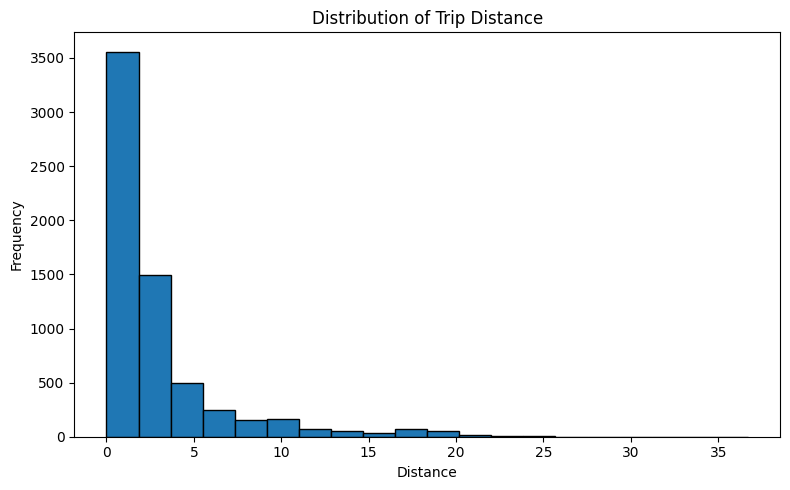

In [ ]:


plt.figure(figsize=(8, 5))

plt.hist(df['distance'], bins=20, edgecolor='black')

plt.title('Distribution of Trip Distance')
plt.xlabel('Distance')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

box plot

<Figure size 900x500 with 0 Axes>

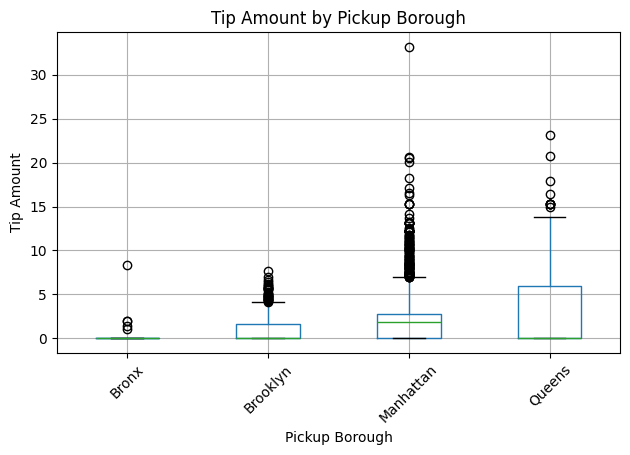

In [ ]:


plt.figure(figsize=(9, 5))

df.boxplot(
    column='tip',
    by='pickup_borough'
)

plt.title('Tip Amount by Pickup Borough')
plt.suptitle('')
plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# **Visualizations using Seaborn**

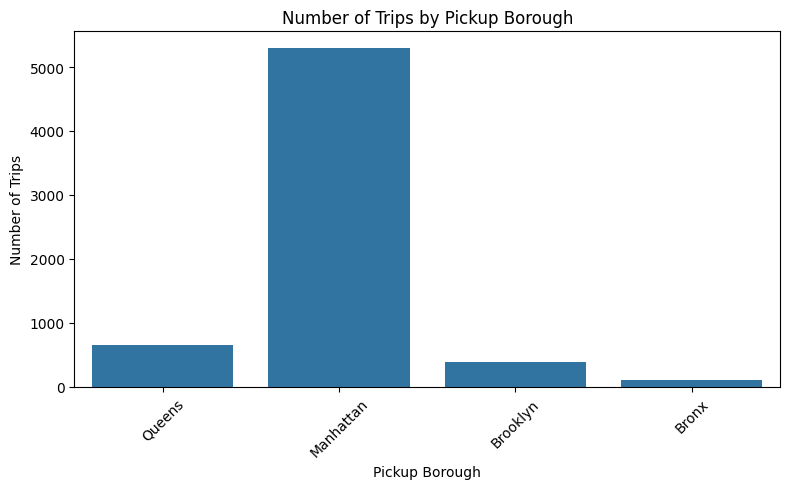

In [ ]:
# Create count plot

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='pickup_borough')

plt.title('Number of Trips by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Number of Trips')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
# Create scatter plot

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='distance',
    y='fare',
    hue='pickup_borough'
)

plt.title('Relationship Between Distance and Fare')
plt.xlabel('Distance')
plt.ylabel('Fare')

plt.tight_layout()
plt.show()

In [ ]:
# Select numerical columns

numeric_data = df[['distance', 'fare', 'tip', 'tolls', 'total']]


In [ ]:
# Calculate correlation

correlation = numeric_data.corr()

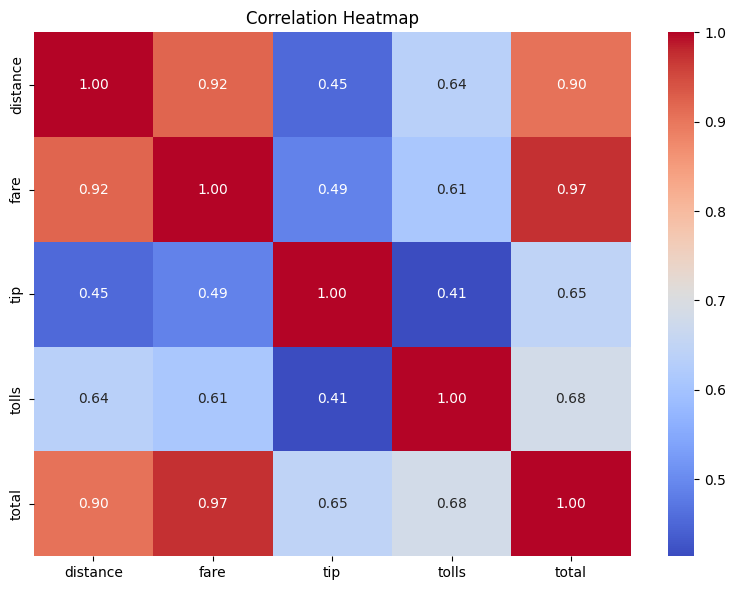

In [ ]:
# Create heatmap

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')

plt.tight_layout()
plt.show()

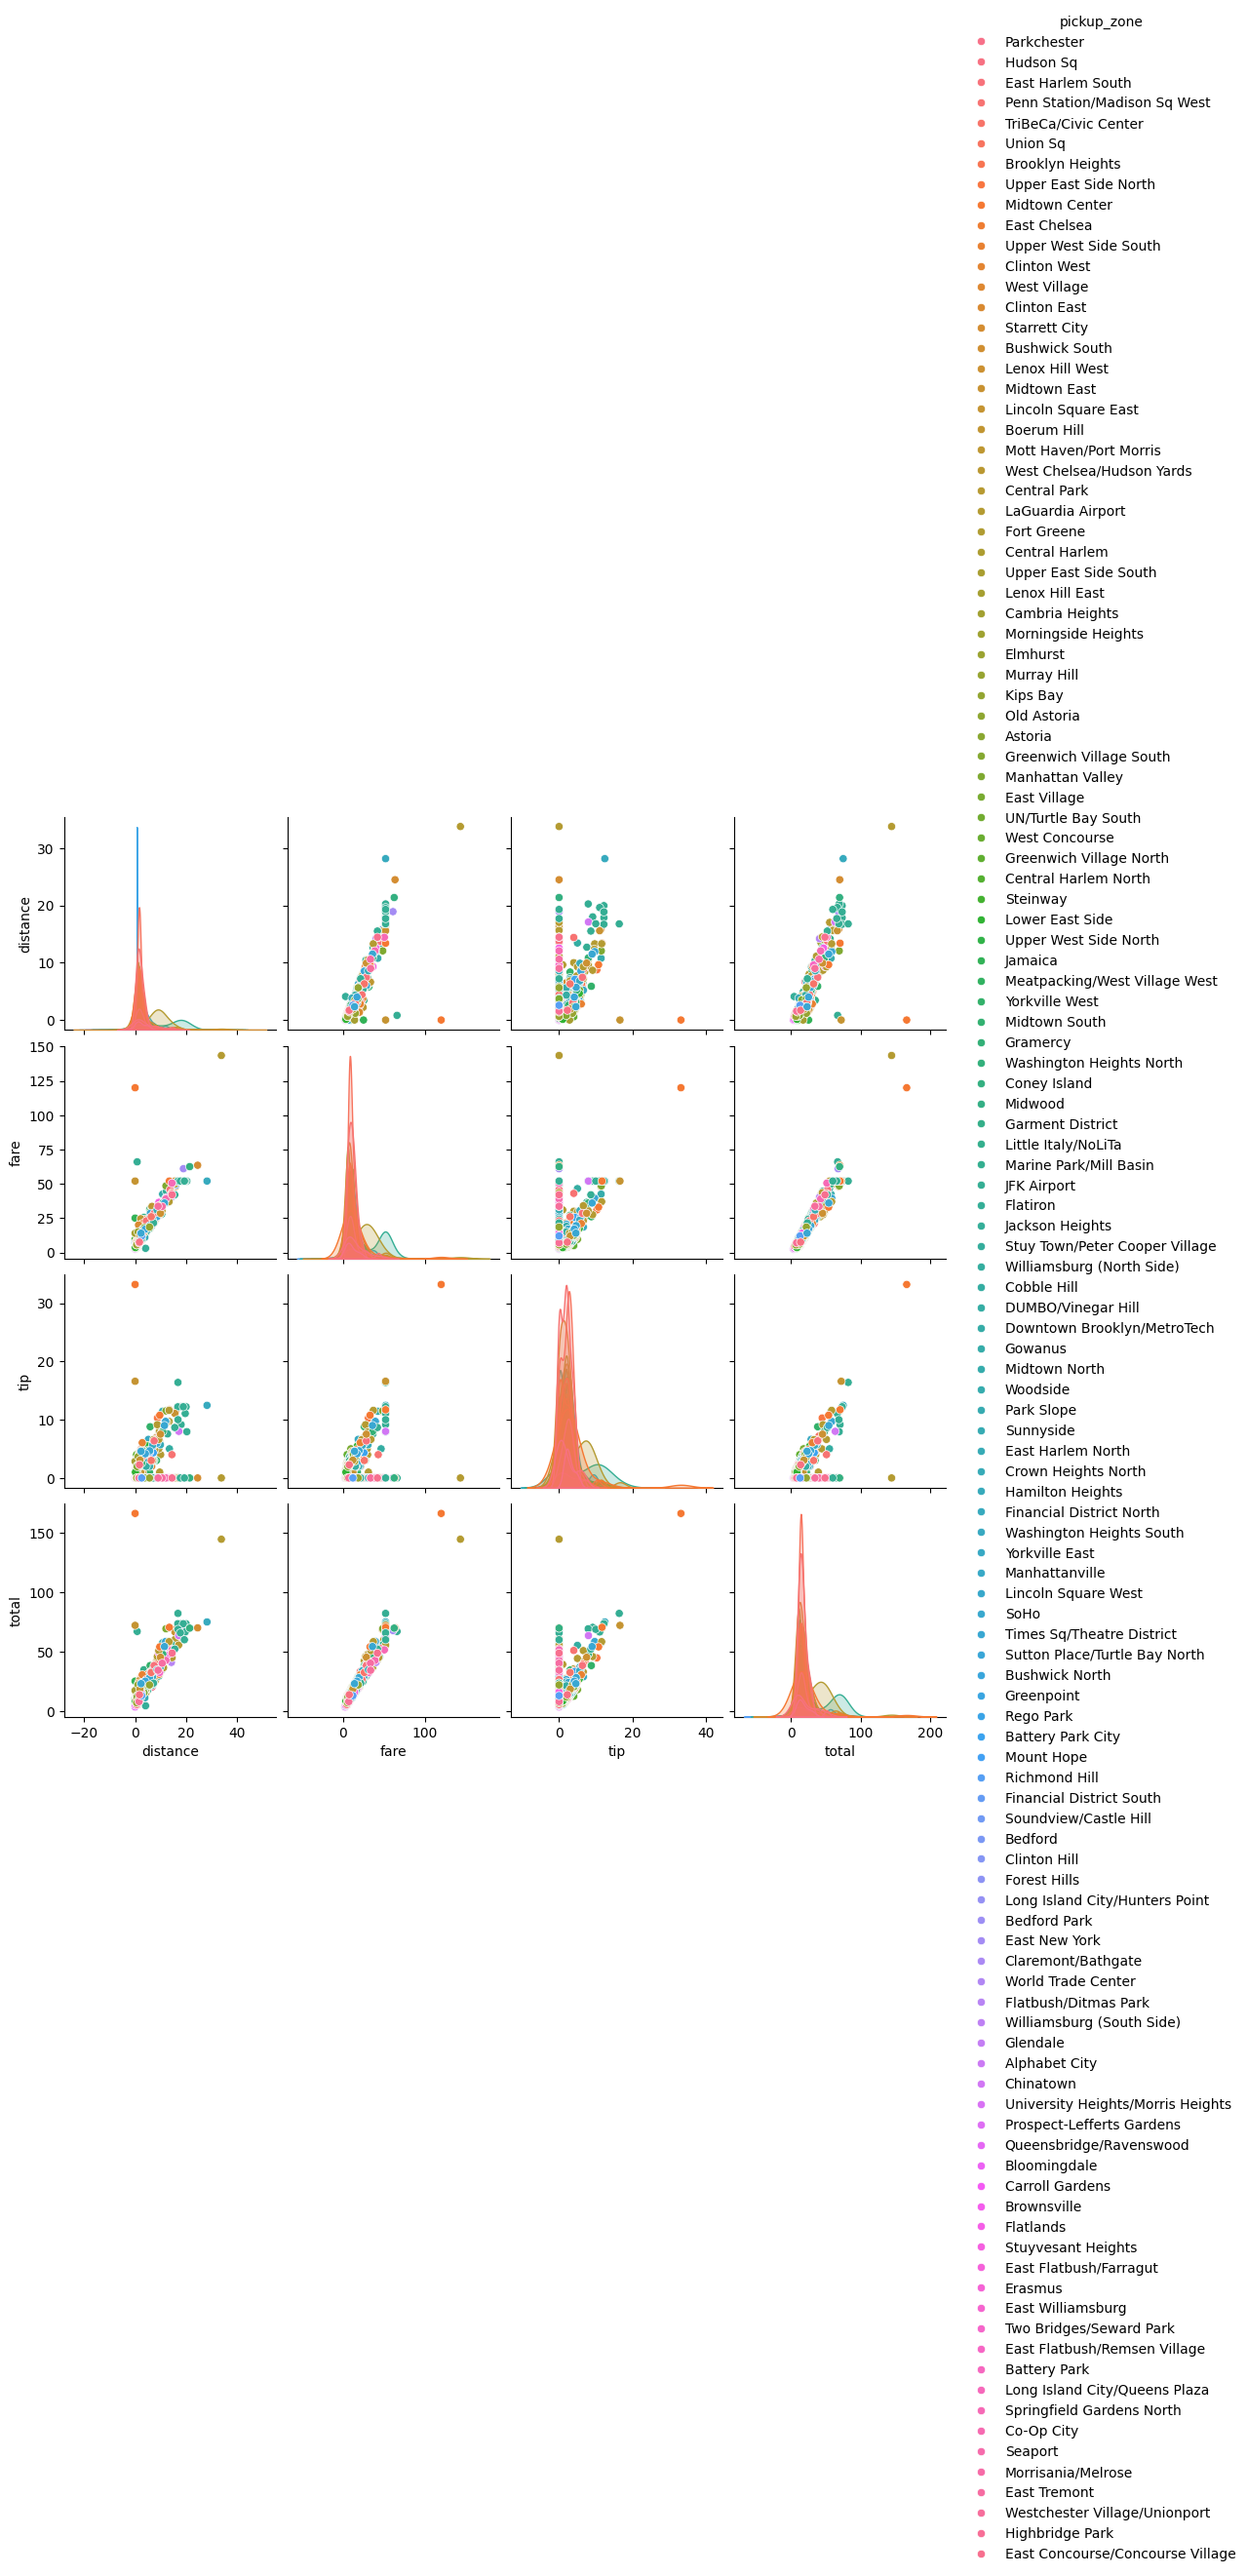

In [ ]:
# Select required columns

pair_data = df[
    ['distance', 'fare', 'tip', 'total', 'pickup_zone']
].dropna()

# Take a sample to make the plot easier to read

pair_data = pair_data.sample(
    n=min(1000, len(pair_data)),
    random_state=42
)

# Create pair plot

sns.pairplot(
    pair_data,
    vars=['distance', 'fare', 'tip', 'total'],
    hue='pickup_zone'
)

plt.show()

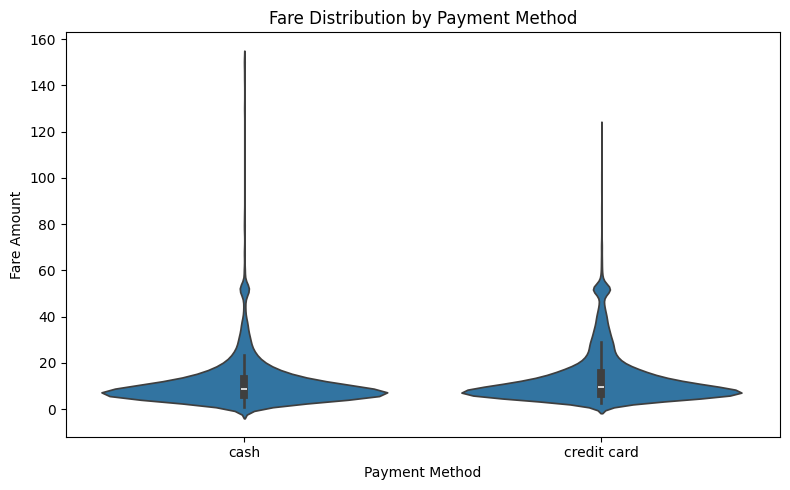

In [ ]:
# Create violin plot

plt.figure(figsize=(8, 5))

sns.violinplot(
    data=df,
    x='payment',
    y='fare'
)

plt.title('Fare Distribution by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Fare Amount')

plt.tight_layout()
plt.show()

In [ ]:


print(df.head())

                  pickup             dropoff  passengers  distance  fare  tip  \
6203 2019-02-28 23:29:03 2019-02-28 23:32:35           1      0.90   5.0  0.0   
884  2019-03-01 00:03:29 2019-03-01 00:13:32           3      2.16  10.0  2.0   
2882 2019-03-01 00:08:32 2019-03-01 00:29:47           3      7.35  22.5  1.0   
4212 2019-03-01 00:15:53 2019-03-01 00:47:58           1      7.00  25.5  7.3   
661  2019-03-01 00:29:22 2019-03-01 00:32:48           4      0.74   4.5  1.0   

      tolls  total   color      payment                    pickup_zone  \
6203    0.0    6.3   green         cash                    Old Astoria   
884     0.0   15.8  yellow  credit card            Lincoln Square East   
2882    0.0   27.3  yellow  credit card                   East Chelsea   
4212    0.0   36.6  yellow  credit card                   West Village   
661     0.0    9.3  yellow  credit card  Meatpacking/West Village West   

                       dropoff_zone pickup_borough dropoff_borough  

In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
Index: 6433 entries, 6203 to 591
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[ns]
 1   dropoff          6433 non-null   datetime64[ns]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   object        
 9   payment          6433 non-null   object        
 10  pickup_zone      6433 non-null   object        
 11  dropoff_zone     6433 non-null   object        
 12  pickup_borough   6433 non-null   object        
 13  dropoff_borough  6433 non-null   object        
dtypes: datetime64[ns](2), float64(5), int64(1),

In [ ]:
print(df.isnull().sum())


pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


In [ ]:
print(df.shape)

(6433, 14)


# Conclusion


In this assignment, i performed data cleaning and visualization using Python. i loaded the Taxis dataset using Seaborn and handled missing values using appropriate techniques. i created different visualizations using Matplotlib, Pandas and Seaborn, including line charts, bar charts, pie charts, histograms, box plots, count plots, scatter plots, heatmaps, pair plots and violin plots.

These visualizations help us understand taxi fare patterns, trip distances, payment methods and relationships between numerical variables.